<a href="https://colab.research.google.com/github/marcellinromero/Analise-Empresas-Unicornio/blob/main/Analise_Unicornio.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 936 entries, 0 to 935
Data columns (total 8 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   ID              936 non-null    int64 
 1   Empresa         936 non-null    object
 2   Valor($)        936 non-null    object
 3   Data de Adesão  936 non-null    object
 4   Pais            936 non-null    object
 5   Cidade          921 non-null    object
 6   Industria       936 non-null    object
 7   Investidores    935 non-null    object
dtypes: int64(1), object(7)
memory usage: 58.6+ KB


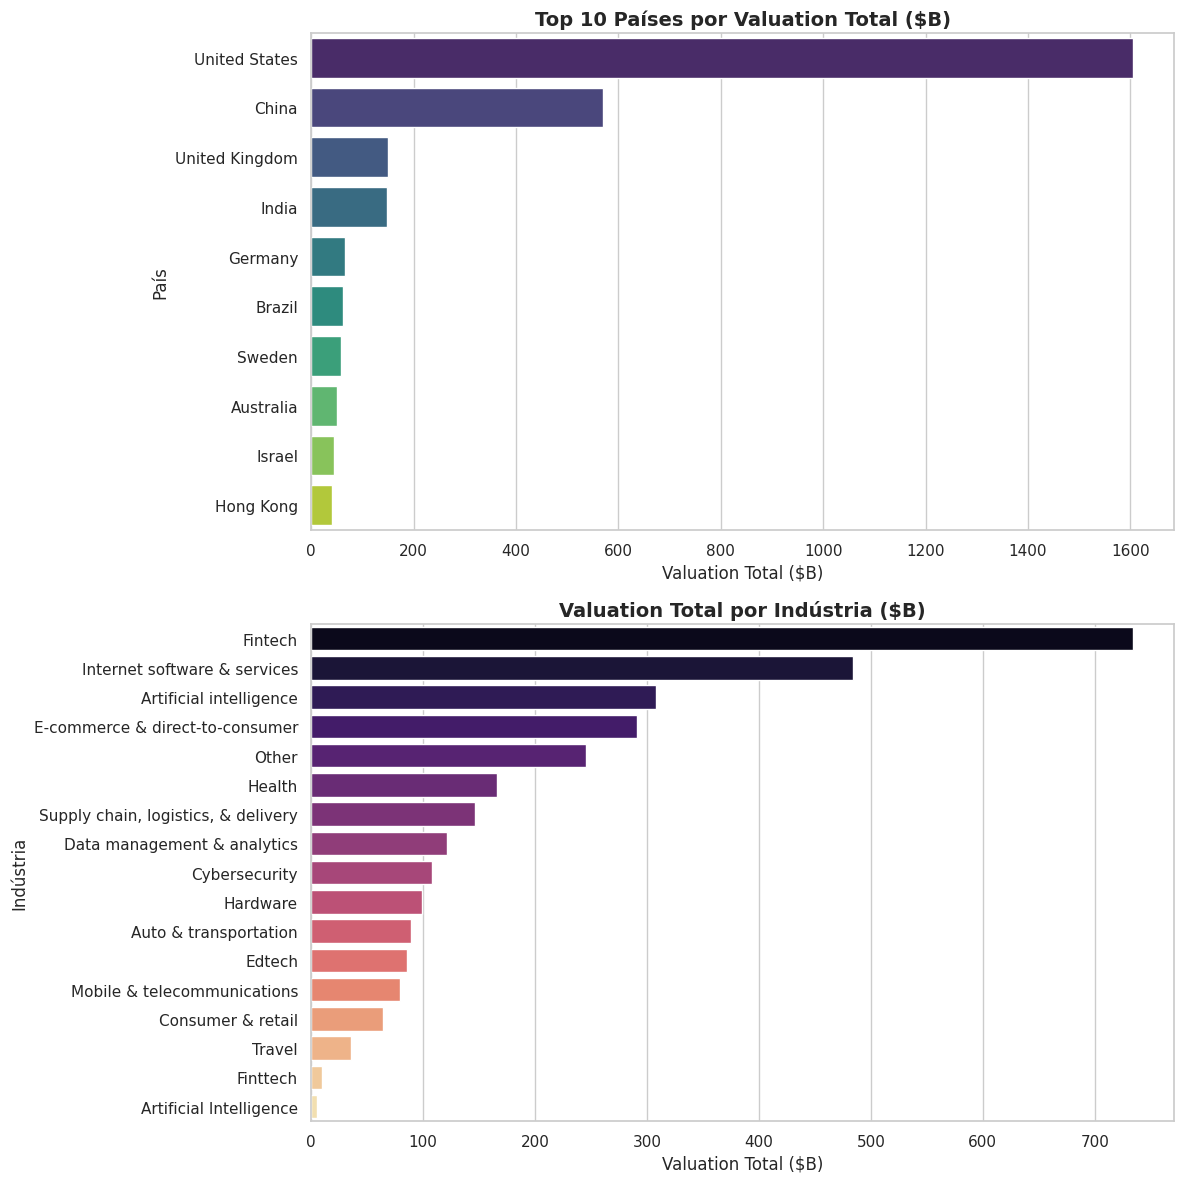

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings("ignore")

#Ler a base de dados

df = pd.read_csv(r'/content/Startups+in+2021+end.csv')
#Verificando o tamanho do dataset
df.shape

#Primeiras 5 linhas do dataset
df.head()

#Renomeando as colunas para facilitar a manipulação dos dados
df.rename(columns={
    'Unnamed: 0': 'ID',
    'Company': 'Empresa',
    'Valuation ($B)': 'Valor($)',
    'Date Joined':'Data de Adesão',
    'Country': 'Pais',
    'City':'Cidade',
    'Industry':'Industria',
    'Select Investors':'Investidores',
}, inplace=True)

# Verificar Tipo de Informação

df.info()

# Removendo o símbolo '$' antes de converter para float a Coluna Valor
df['Valor($)'] = df['Valor($)'].str.replace('$', '').astype(float)

#Tranformando a coluna Data de Adesão para Datetime

df['Data de Adesão'] = pd.to_datetime(df['Data de Adesão'])

#Tratando os Nulos na Coluna Cidades

df[df["Cidade"].isnull()]

df["Cidade"] = df["Cidade"].fillna('Desconhecida')

df[df["Cidade"] == "Desconhecida"]

#Tratando Nulo Coluna Investidores

df["Investidores"] = df["Investidores"].fillna('Desconhecido')

df[df["Investidores"] == "Desconhecido"]


# tratando erros de escrita

df['Pais'].unique()

sorted(df['Pais'].unique())

df= df.replace('United States,', 'United States')
df= df.replace('Indonesia,', 'Indonesia')
df

#Agrupando os dados

valor_por_pais = df.groupby('Pais')['Valor($)'].sum().sort_values(ascending=False)
valor_por_pais

valor_por_industria = df.groupby('Industria')['Valor($)'].sum().sort_values(ascending=False)
valor_por_industria

#Definir o estilo dos gráficos
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(nrows=2, ncols=1, figsize=(12, 12))

#Gráfico de Valor por País (Top 10)
sns.barplot(
    x=valor_por_pais.head(10).values,
    y=valor_por_pais.head(10).index,
    ax=axes[0],
    palette="viridis"
)
axes[0].set_title('Top 10 Países por Valuation Total ($B)', fontsize=14, fontweight='bold')
axes[0].set_xlabel('Valuation Total ($B)', fontsize=12)
axes[0].set_ylabel('País', fontsize=12)

#Gráfico de Valor por Indústria
sns.barplot(
    x=valor_por_industria.values,
    y=valor_por_industria.index,
    ax=axes[1],
    palette="magma"
)
axes[1].set_title('Valuation Total por Indústria ($B)', fontsize=14, fontweight='bold')
axes[1].set_xlabel('Valuation Total ($B)', fontsize=12)
axes[1].set_ylabel('Indústria', fontsize=12)

plt.tight_layout()
plt.show()
